# GenAI Assignment 2: Clinical Trial Eligibility with Transformer Inference Mechanisms

**Course:** Generative AI
**Author:** Muhammad Hamza

---

This notebook runs the complete pipeline:
1. **Task 1:** Dataset preparation, model selection & QLoRA fine-tuning
2. **Task 2:** Comprehensive evaluation with classification + evidence metrics
3. **Task 3:** KV-Cached autoregressive generation
4. **Task 4:** Tiled attention with online softmax (FlashAttention-style)
5. **Task 5:** Speculative decoding
6. **Task 6:** Interactive Streamlit application

**Hardware:** Google Colab T4 GPU recommended

In [2]:
# ============================================================
# Environment Setup
# ============================================================
!pip install -q torch transformers datasets peft bitsandbytes accelerate trl
!pip install -q numpy pandas scikit-learn matplotlib seaborn tqdm
!pip install -q streamlit plotly sentencepiece protobuf huggingface_hub pyyaml

import os
if not os.path.exists('src'):
    !git clone https://github.com/hamzaa112233/GenAI-Assignment2.git temp_repo
    !cp -r temp_repo/* .
    !rm -rf temp_repo

import sys
sys.path.insert(0, '.')
os.makedirs('reports/figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Memory: 15.6 GB


---
## Task 1a: Dataset Preparation & Patient-Grouped Splitting

Download `ncbi/TrialGPT-Criterion-Annotations`, create strict patient-grouped splits (seed=42, 37/8/8), remove GPT-4 leakage columns, and save split manifest.

In [3]:
from src.data.dataset import prepare_datasets

ds_dict, patient_splits = prepare_datasets(output_dir='./outputs')

print(f"\nTrain: {len(ds_dict['train'])} samples")
print(f"Validation: {len(ds_dict['validation'])} samples")
print(f"Test: {len(ds_dict['test'])} samples")

# Show a sample
sample = ds_dict['train'][0]
print(f"\n--- Sample ---")
print(f"Patient ID: {sample['patient_id']}")
print(f"Input (first 300 chars): {sample['input'][:300]}...")
print(f"Output: {sample['output']}")

Clinical Trial Eligibility - Data Preparation Pipeline

[1/6] Downloading TrialGPT-Criterion-Annotations...
  -> Loaded 1015 annotations
  -> Columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training']

[2/6] Extracting patient IDs...
  -> Found 53 unique patients

[3/6] Creating patient-grouped splits...
  -> train: 37 patients
  -> validation: 8 patients
  -> test: 8 patients

[4/6] Splitting dataset and removing leakage columns...
  -> train: 603 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibility', 'training']
  -> validation: 206 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibilit

Formatting train:   0%|          | 0/603 [00:00<?, ? examples/s]

Formatting validation:   0%|          | 0/206 [00:00<?, ? examples/s]

Formatting test:   0%|          | 0/206 [00:00<?, ? examples/s]


[6/6] Saving split manifest...
  -> Manifest saved to: /content/outputs/split_manifest.json

Data Preparation Complete!
  train       :   603 samples
  validation  :   206 samples
  test        :   206 samples


Train: 603 samples
Validation: 206 samples
Test: 206 samples

--- Sample ---
Patient ID: sigir-20143
Input (first 300 chars): ### System:
You are a clinical trial eligibility assessment system. Given a patient description with numbered sentences, a criterion type (inclusion or exclusion), and the criterion text, determine the patient's eligibility status and identify the supporting sentences from the patient description.

...
Output: {"eligibility": "not enough information", "supporting_sentences": [0]}


## Task 1b: Model Architecture Selection

We compared:
- **Qwen2.5-1.5B-Instruct** (selected): Best instruction-following, robust JSON output, compatible draft model available
- **Llama-3.2-1B-Instruct**: Competitive but weaker structured output
- **SmolLM2-1.7B-Instruct**: Similar size but weaker clinical reasoning

### Load Model with QLoRA

In [4]:
from src.models.model import load_model_for_training

model, tokenizer = load_model_for_training(
    model_name='Qwen/Qwen2.5-1.5B-Instruct',
    lora_r=16, lora_alpha=32, lora_dropout=0.05
)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Trainable parameters: 18,464,768 / 907,081,216 (2.04%)


## Task 1c: Fine-Tuning

In [10]:
# 1. Pull latest code from GitHub
!rm -rf temp_repo
!git clone -q https://github.com/hamzaa112233/GenAI-Assignment2.git temp_repo
!cp -rf temp_repo/* .
!rm -rf temp_repo

# 2. Purge stale in-memory modules so Python re-imports the clean code
import sys
for m in list(sys.modules.keys()):
    if m.startswith('src'):
        del sys.modules[m]

print("Updated and memory cache cleared! You can now run Task 1c.")

Updated and memory cache cleared! You can now run Task 1c.


In [11]:
from src.models.train import main as train_main

train_results = train_main(config_path='configs/training_config.yaml', model=model, tokenizer=tokenizer)

Clinical Trial Eligibility - Data Preparation Pipeline

[1/6] Downloading TrialGPT-Criterion-Annotations...
  -> Loaded 1015 annotations
  -> Columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training']

[2/6] Extracting patient IDs...
  -> Found 53 unique patients

[3/6] Creating patient-grouped splits...
  -> train: 37 patients
  -> validation: 8 patients
  -> test: 8 patients

[4/6] Splitting dataset and removing leakage columns...
  -> train: 603 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibility', 'training']
  -> validation: 206 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibilit

Formatting train:   0%|          | 0/603 [00:00<?, ? examples/s]

Formatting validation:   0%|          | 0/206 [00:00<?, ? examples/s]

Formatting test:   0%|          | 0/206 [00:00<?, ? examples/s]


[6/6] Saving split manifest...
  -> Manifest saved to: /content/outputs/split_manifest.json

Data Preparation Complete!
  train       :   603 samples
  validation  :   206 samples
  test        :   206 samples



Tokenising train:   0%|          | 0/603 [00:00<?, ? examples/s]

... (9 outputs left out)

***** train metrics *****
  epoch                    =        3.0
  total_flos               =  5597234GF
  train_loss               =     0.1732
  train_runtime            = 0:16:11.34
  train_samples_per_second =      1.862
  train_steps_per_second   =      0.117


/usr/local/lib/python3.13/dist-packages/transformers/tokenization_utils_base.py:2387: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


Training Loss,Validation Loss,Epoch
0.036101,0.057915,3


***** eval metrics *****
  eval_loss = 0.0579

  INFERENCE AFTER TRAINING

--- Sample 1 [AFTER] ---
Criterion (inclusion): Patients of chronic stable angina with abnormal Exercise Myocardial Perfusion Spect Scan with revers...
Ground truth: not enough information
Generated:
{"eligibility": "not enough information", "evidence_sentence_ids": [], "rationale": "Criterion assessment based on evidence sentences []."}

--- Sample 2 [AFTER] ---
Criterion (inclusion): Male and female...
Ground truth: included
Generated:
{"eligibility": "included", "evidence_sentence_ids": [0], "rationale": "Criterion assessment based on evidence sentences [0]."}

--- Sample 3 [AFTER] ---
Criterion (inclusion): Age 25 to 65 years...
Ground truth: included
Generated:
{"eligibility": "included", "evidence_sentence_ids": [0], "rationale": "Criterion assessment based on evidence sentences [0]."}

--- Sample 4 [AFTER] ---
Criterion (inclusion): Patient must understand and be willing, able and likely to comply with al

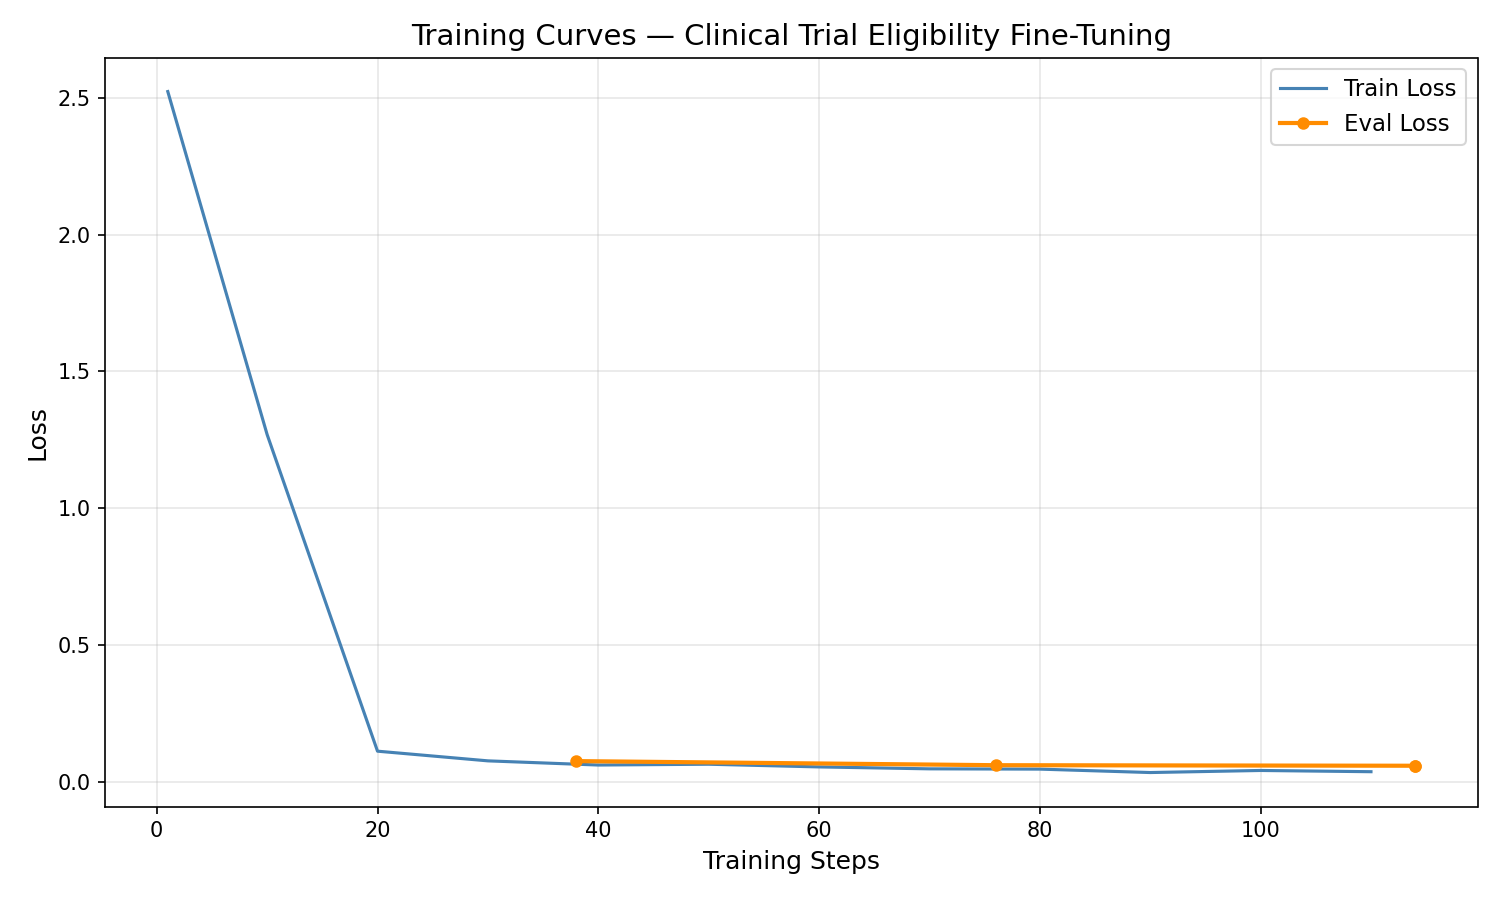

In [12]:
# Display training curves
from IPython.display import Image, display
display(Image(filename='reports/figures/training_curves.png'))

---
## Task 2: Criterion-Level Eligibility Evaluation

Evaluate on the held-out test set with:
- Multi-class classification metrics (Macro-F1, Accuracy, per-class P/R/F1)
- Evidence sentence retrieval metrics (Micro/Macro P/R/F1)
- Confusion matrices (overall, inclusion, exclusion)
- Error analysis (8 distinct categories)

In [18]:
# 1. Pull latest fix
!rm -rf temp_repo
!git clone -q https://github.com/hamzaa112233/GenAI-Assignment2.git temp_repo
!cp -rf temp_repo/* .
!rm -rf temp_repo

# 2. Rescue test predictions from traceback if cache not already saved
import sys, json, os
os.makedirs("reports", exist_ok=True)
recovered = None
tb = getattr(sys, "last_traceback", None)
while tb is not None:
    if "raw_outputs" in tb.tb_frame.f_locals:
        recovered = tb.tb_frame.f_locals["raw_outputs"]
        break
    tb = tb.tb_next

if recovered and len(recovered) == 206 and not os.path.exists("reports/test_raw_outputs_cache.json"):
    with open("reports/test_raw_outputs_cache.json", "w", encoding="utf-8") as f:
        json.dump(recovered, f)
    print(f"Rescued {len(recovered)} test predictions from memory cache!")

# 3. Purge cached modules from memory
for m in list(sys.modules.keys()):
    if m.startswith("src"):
        del sys.modules[m]

print("Ready!")

Ready!


In [19]:
from src.evaluation.evaluate import run_full_evaluation

eval_results = run_full_evaluation(
    adapter_path='outputs/best_adapter',
    base_model_name='Qwen/Qwen2.5-1.5B-Instruct',
    output_dir='reports'
)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Clinical Trial Eligibility - Data Preparation Pipeline

[1/6] Downloading TrialGPT-Criterion-Annotations...
  -> Loaded 1015 annotations
  -> Columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'gpt4_explanation', 'explanation_correctness', 'gpt4_sentences', 'expert_sentences', 'gpt4_eligibility', 'expert_eligibility', 'training']

[2/6] Extracting patient IDs...
  -> Found 53 unique patients

[3/6] Creating patient-grouped splits...
  -> train: 37 patients
  -> validation: 8 patients
  -> test: 8 patients

[4/6] Splitting dataset and removing leakage columns...
  -> train: 603 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibility', 'training']
  -> validation: 206 samples, columns: ['annotation_id', 'patient_id', 'note', 'trial_id', 'trial_title', 'criterion_type', 'criterion_text', 'expert_sentences', 'expert_eligibilit

Formatting train:   0%|          | 0/603 [00:00<?, ? examples/s]

Formatting validation:   0%|          | 0/206 [00:00<?, ? examples/s]

Formatting test:   0%|          | 0/206 [00:00<?, ? examples/s]


[6/6] Saving split manifest...
  -> Manifest saved to: /content/outputs/split_manifest.json

Data Preparation Complete!
  train       :   603 samples
  validation  :   206 samples
  test        :   206 samples


EVALUATION SUMMARY
  Test samples:        206
  Parse success rate:  100.0%
  Macro-F1:            0.4277
  Accuracy:            0.7233
  Evidence Micro-F1:   0.5513




confusion_matrix_overall.png:


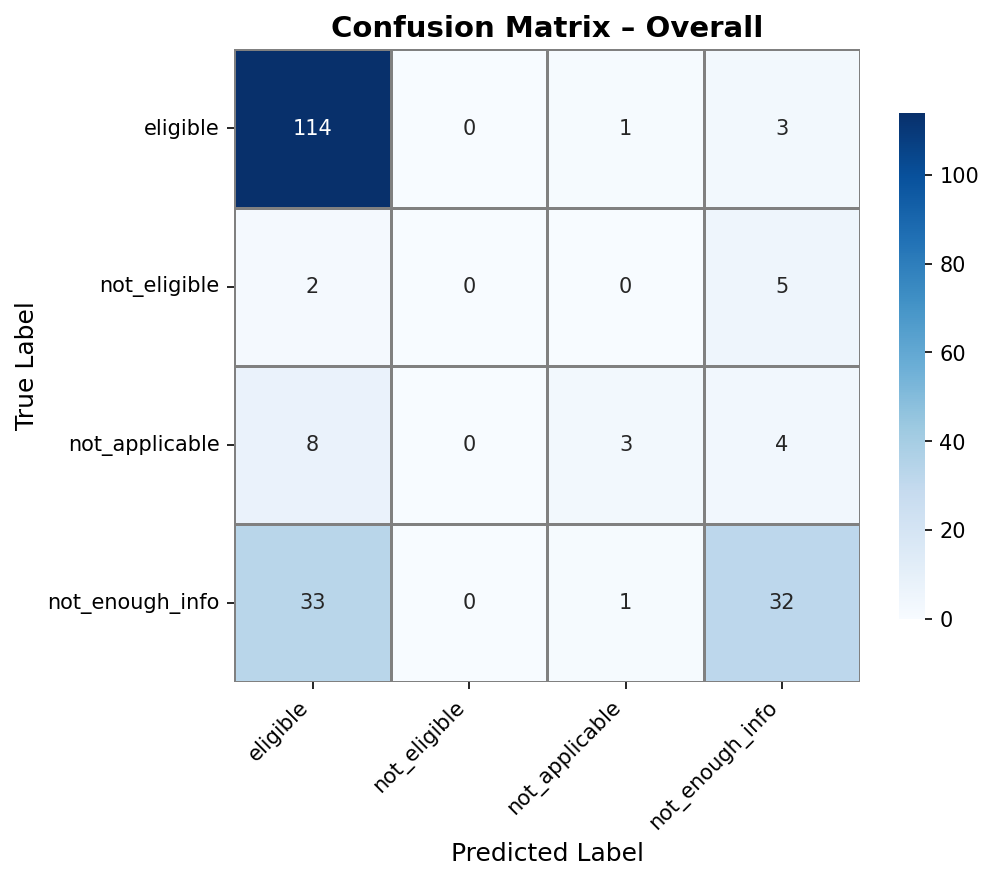


confusion_matrix_inclusion.png:


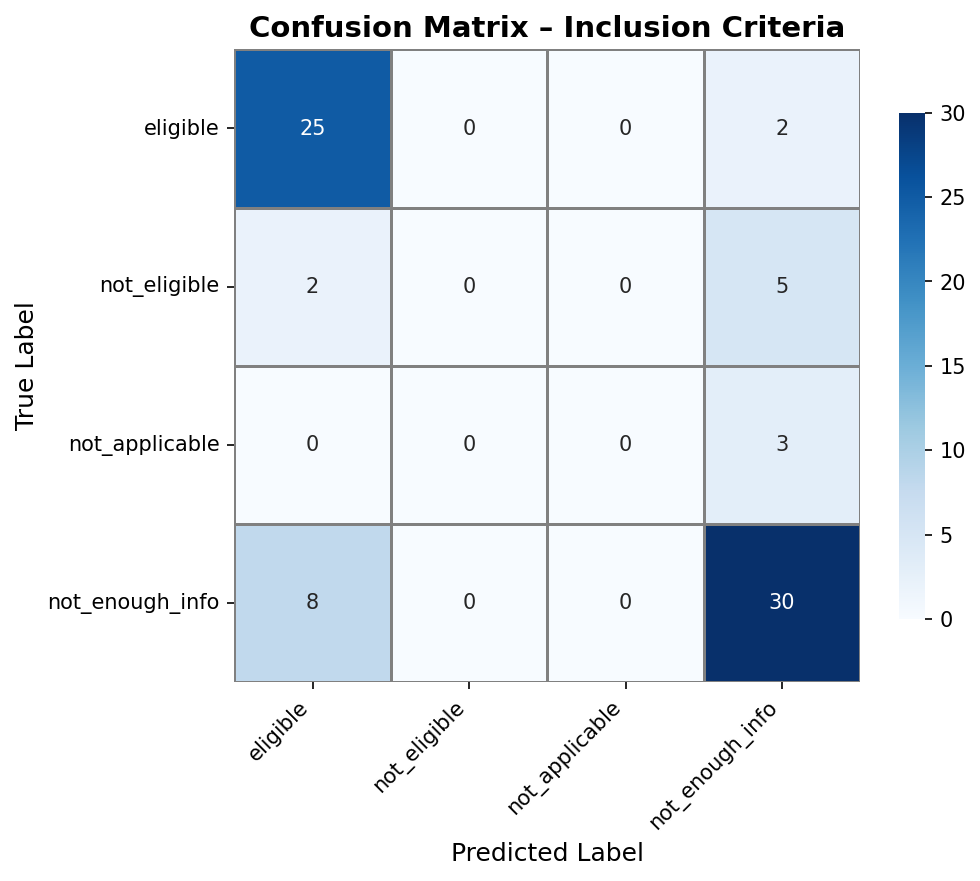


confusion_matrix_exclusion.png:


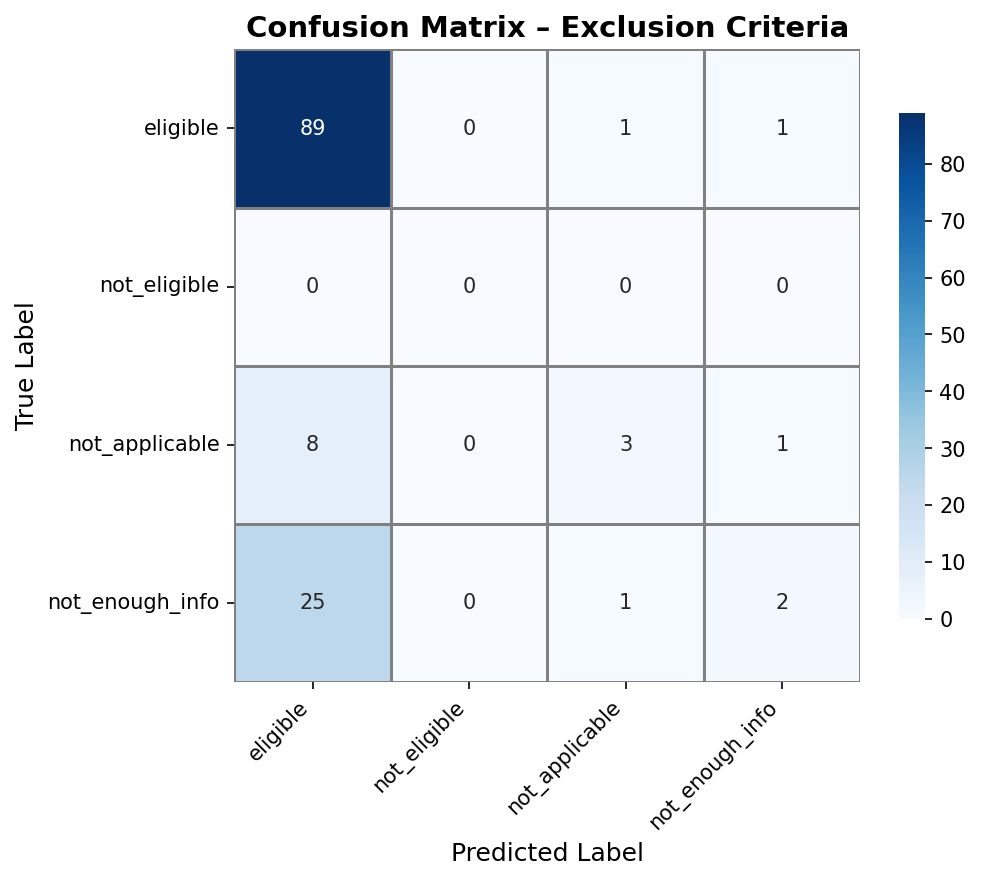

In [20]:
# Display confusion matrices
from IPython.display import Image, display
import os

for fig_name in ['confusion_matrix_overall.png', 'confusion_matrix_inclusion.png', 'confusion_matrix_exclusion.png']:
    path = f'reports/figures/{fig_name}'
    if os.path.exists(path):
        print(f'\n{fig_name}:')
        display(Image(filename=path))

---
## Task 3: KV-Cached Autoregressive Generation

Implement and compare:
- **Uncached**: Full recomputation at every decode step
- **KV-Cached**: Manual past_key_values management, only new token fed per step

Verify token-level equivalence and benchmark performance.

In [22]:
# 1. Pull the fix from GitHub
!rm -rf temp_repo
!git clone -q https://github.com/hamzaa112233/GenAI-Assignment2.git temp_repo
!cp -rf temp_repo/* .
!rm -rf temp_repo

# 2. Purge cached modules from memory
import sys
for m in list(sys.modules.keys()):
    if m.startswith("src"):
        del sys.modules[m]

print("Ready! Re-run Task 3 now.")

Ready! Re-run Task 3 now.


In [23]:
from src.inference.kv_cache import verify_equivalence, benchmark

# Step 1: Verify token-level equivalence
equiv = verify_equivalence(model_name='Qwen/Qwen2.5-1.5B-Instruct')

[verify_equivalence] Loading model 'Qwen/Qwen2.5-1.5B-Instruct' on cuda ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]


KV-Cache Equivalence Verification
Prompt                                                       Tokens  Match
------------------------------------------------------------ ------ ------
  Summarize the eligibility criteria for this clinical tr...     64      ✓
  The patient is a 45-year-old male diagnosed with type 2...     64      ✓
  List the inclusion and exclusion criteria for the follo...     64      ✓

Overall: ALL MATCH ✓




STEP 2: Performance Benchmark
[benchmark] Loading model 'Qwen/Qwen2.5-1.5B-Instruct' on cuda ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  Warming up uncached generator (3 iters) ...
  Benchmarking uncached generator (5 iters) ...
  Warming up cached generator (3 iters) ...
  Benchmarking cached generator (5 iters) ...

KV-Cache Benchmark Results
Metric                                Uncached            KV-Cached
------------------------- -------------------- --------------------
  prefill_time_s                        0.0464               0.0415
  decode_time_s                         2.6629               2.3542
  total_time_s                          2.7093               2.3957
  tokens_per_sec                          23.8                 26.9
  peak_memory_mb                        8740.5               8699.6

  Speedup (total time): 1.13x

[benchmark] Figure saved to reports/figures/kv_cache_benchmark.png


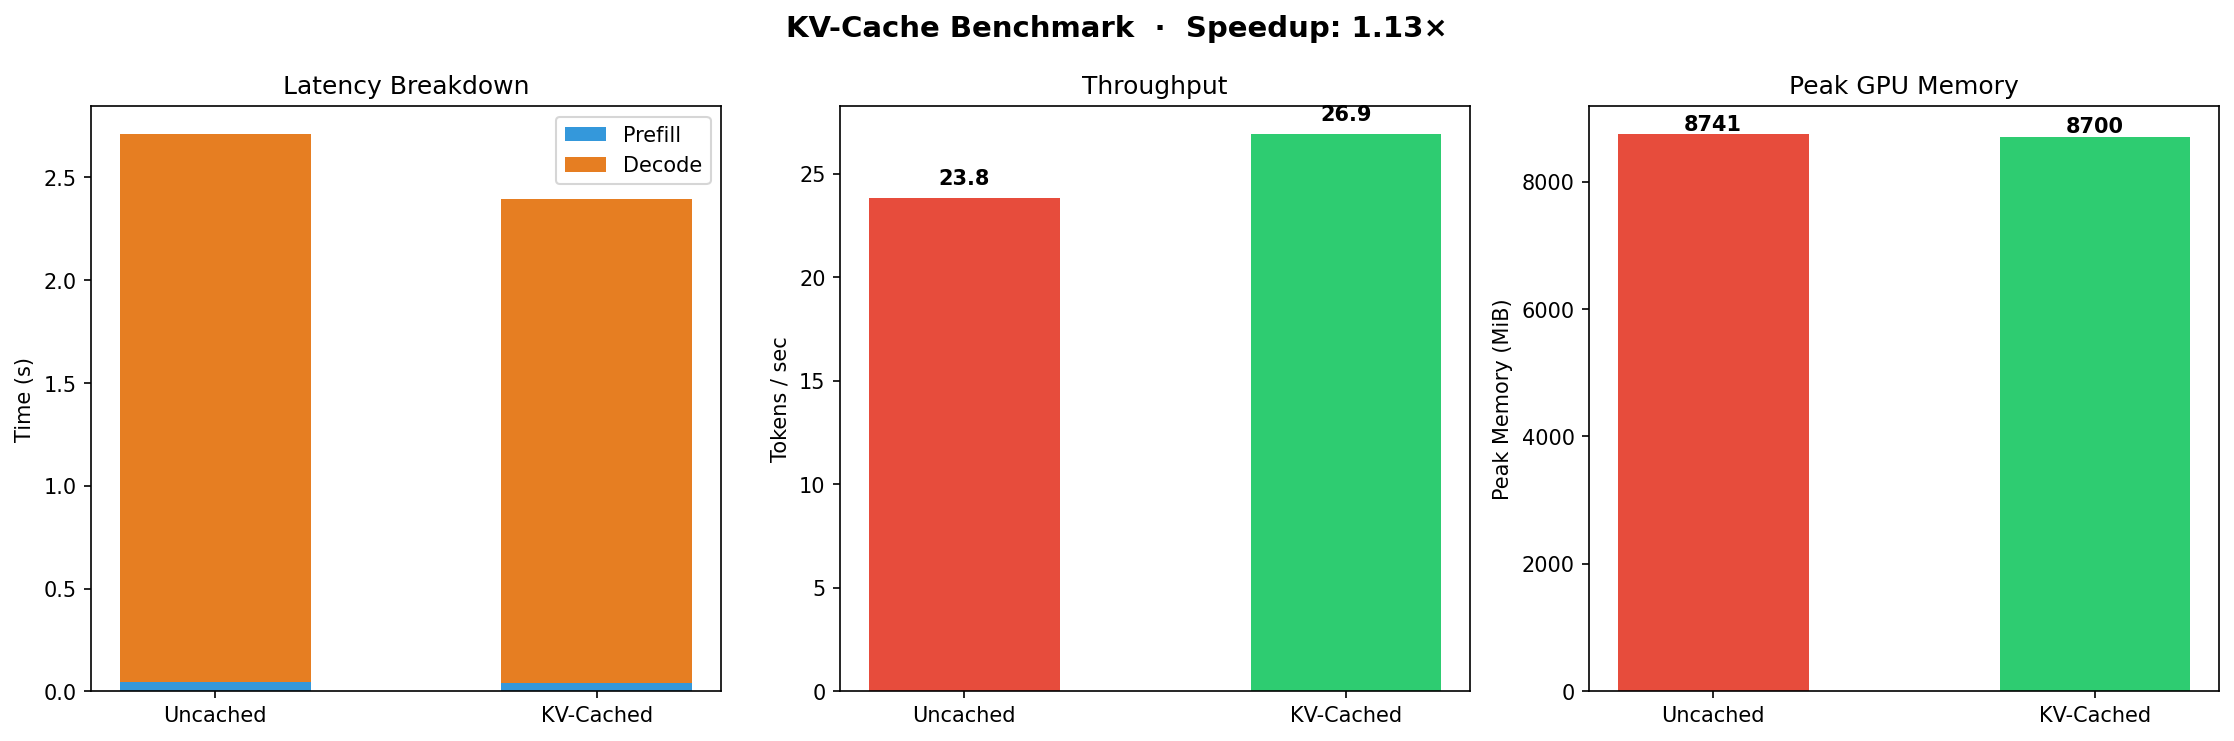

In [24]:
# Benchmark KV-cached vs uncached generation
print('\n' + '='*60)
print('STEP 2: Performance Benchmark')
print('='*60)
kv_results = benchmark(model_name='Qwen/Qwen2.5-1.5B-Instruct')

from IPython.display import Image, display
display(Image(filename='reports/figures/kv_cache_benchmark.png'))

In [ ]:
kv_results = benchmark(model_name='Qwen/Qwen2.5-1.5B-Instruct')

---
## Task 4: Tiled Attention with Online Softmax

Implement FlashAttention-style blocked computation:
- Standard SDPA reference with causal masking and stable softmax
- Tiled online-softmax attention with running max (m), normalizer (l), and output rescaling
- Validate numerical agreement within 1e-4 tolerance

In [25]:
from src.inference.tiled_attention import validate_numerical_agreement, benchmark_attention

# Validate numerical agreement across multiple shapes
print('='*60)
print('STEP 1: Numerical Agreement Validation')
print('='*60)
agreement = validate_numerical_agreement()

STEP 1: Numerical Agreement Validation

Tiled Attention – Numerical Agreement Validation
  Shape                           Block   MaxAbsDiff   Status
  ------------------------------ ------ ------------ --------
  (1, 8, 64, 64)                     32     3.58e-07   ✓ PASS
  (1, 8, 64, 64)                     64     4.17e-07   ✓ PASS
  (2, 12, 128, 64)                   32     5.96e-07   ✓ PASS
  (2, 12, 128, 64)                   64     5.96e-07   ✓ PASS
  (1, 8, 256, 64)                    32     4.77e-07   ✓ PASS
  (1, 8, 256, 64)                    64     4.77e-07   ✓ PASS
  (4, 16, 512, 64)                   32     9.54e-07   ✓ PASS
  (4, 16, 512, 64)                   64     9.54e-07   ✓ PASS

  Overall: ALL PASSED ✓




STEP 2: Runtime & Memory Benchmark

Tiled Attention Benchmark
    SeqLen   Std Time (ms)   Tiled Time (ms)   Std Mem (MiB)   Tiled Mem (MiB)
  -------- --------------- ----------------- --------------- -----------------
       128            1.10              3.89          5754.1            5753.1
       256            1.14              9.89          5761.1            5754.1
       512            1.36             38.39          5786.6            5756.1
      1024            3.54            164.37          5886.6            5760.3

  Analysis:
  The tiled (online-softmax) implementation avoids materialising the full
  (seq × seq) attention matrix, giving it a lower memory footprint for long
  sequences.  However, because it is written with explicit Python for-loops
  over tiles (no fused CUDA kernels), the runtime is dominated by Python
  dispatch overhead and many small CUDA kernel launches.  A true FlashAttention
  CUDA kernel fuses all tile operations into a single kernel launch wit

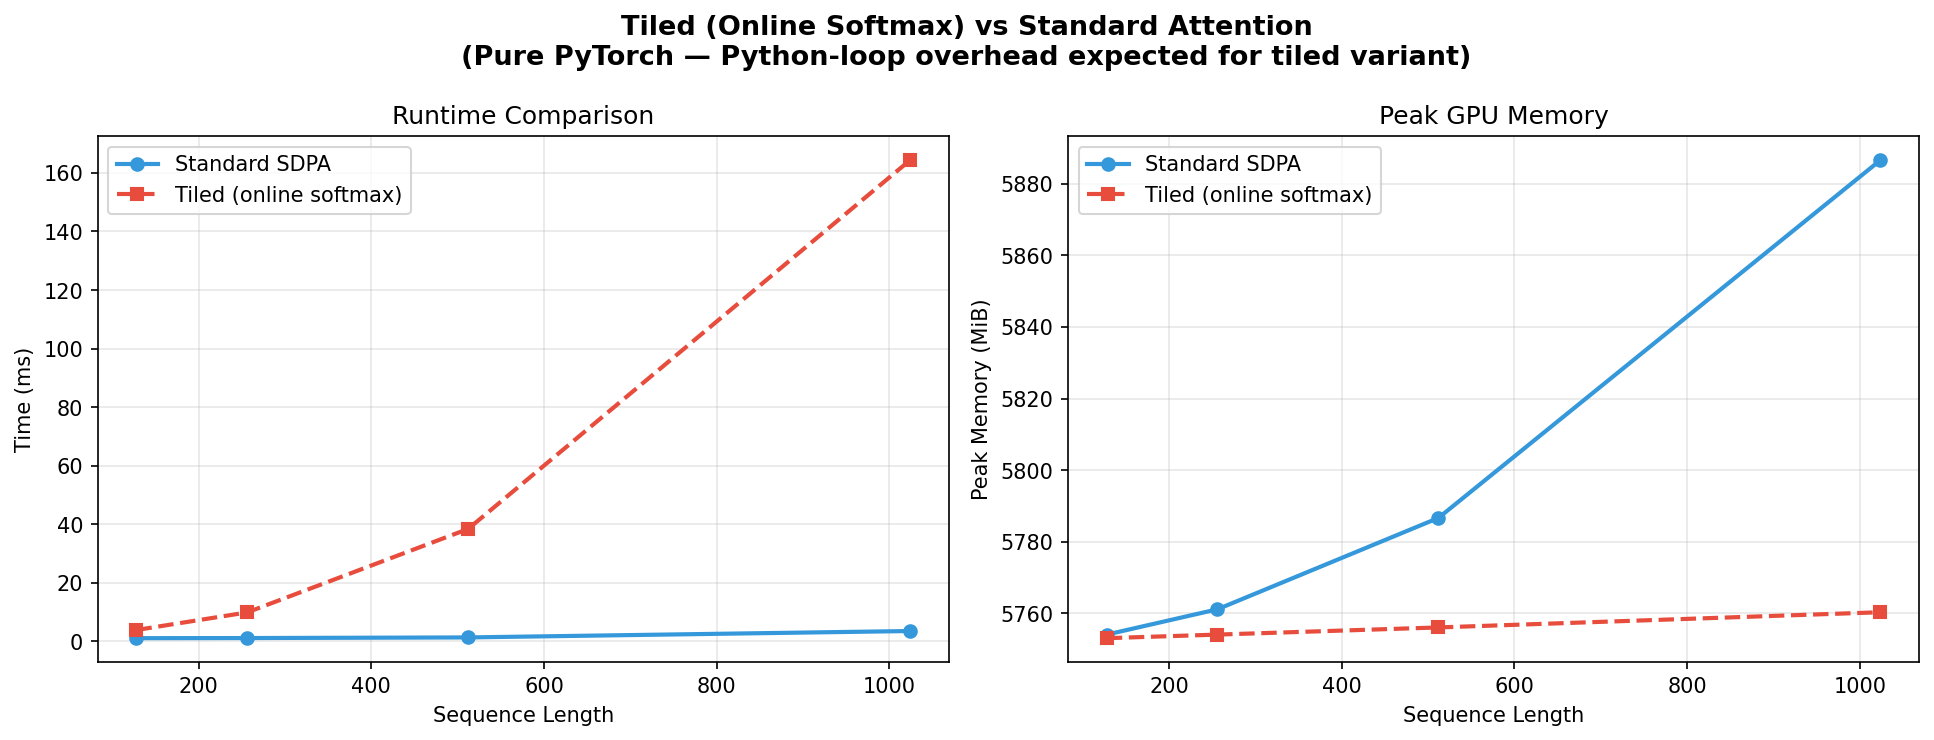

In [26]:
# Benchmark runtime and memory
print('\n' + '='*60)
print('STEP 2: Runtime & Memory Benchmark')
print('='*60)
attn_results = benchmark_attention()

from IPython.display import Image, display
display(Image(filename='reports/figures/tiled_attention_benchmark.png'))

---
## Task 5: Greedy Speculative Decoding

- Draft model: Qwen2.5-0.5B-Instruct
- Target model: Qwen2.5-1.5B-Instruct
- K=5 candidate tokens per iteration
- Verify token equivalence to standard greedy target-only decoding

In [27]:
from src.inference.speculative import verify_equivalence as spec_verify, benchmark as spec_benchmark

# Verify token-level equivalence
print('='*60)
print('STEP 1: Token Equivalence Verification')
print('='*60)
spec_equiv = spec_verify(
    draft_model_name='Qwen/Qwen2.5-0.5B-Instruct',
    target_model_name='Qwen/Qwen2.5-1.5B-Instruct'
)

STEP 1: Token Equivalence Verification

Speculative Decoding – Token Equivalence Verification


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[SpeculativeDecoder] Loading tokenizer from Qwen/Qwen2.5-1.5B-Instruct ...
[SpeculativeDecoder] Loading draft model: Qwen/Qwen2.5-0.5B-Instruct ...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[SpeculativeDecoder] Loading target model: Qwen/Qwen2.5-1.5B-Instruct ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[SpeculativeDecoder] Ready.

  Prompt                                                   RefLen  SpecLen  Match
  ------------------------------------------------------- ------- -------- ------
  Summarize the eligibility criteria for this clinical...      64       64      ✗
    First mismatch at pos 1: ref=785, spec=40634
  The patient is a 45-year-old male diagnosed with typ...      64       64      ✗
    First mismatch at pos 1: ref=32, spec=13
  List the inclusion and exclusion criteria for the fo...      64       64      ✗
    First mismatch at pos 1: ref=85145, spec=3920

  Overall: MISMATCH FOUND ✗




STEP 2: Speculative Decoding Benchmark


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[SpeculativeDecoder] Loading tokenizer from Qwen/Qwen2.5-1.5B-Instruct ...
[SpeculativeDecoder] Loading draft model: Qwen/Qwen2.5-0.5B-Instruct ...


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[SpeculativeDecoder] Loading target model: Qwen/Qwen2.5-1.5B-Instruct ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[SpeculativeDecoder] Ready.
  Warming up target_only (2 iters) ...
  Benchmarking target_only (3 iters) ...
  Warming up speculative (2 iters) ...
  Benchmarking speculative (3 iters) ...

Speculative Decoding Benchmark Results
  Metric                           Target-Only        Speculative
  ------------------------- ------------------ ------------------
  latency_s                             2.4250            15.7033
  tokens_per_sec                          26.5                4.1
  peak_memory_mb                       12598.1            12630.8
  acceptance_rate (α)                      N/A              0.039

  Speedup: 0.15x

[benchmark] Figure saved to reports/figures/speculative_benchmark.png


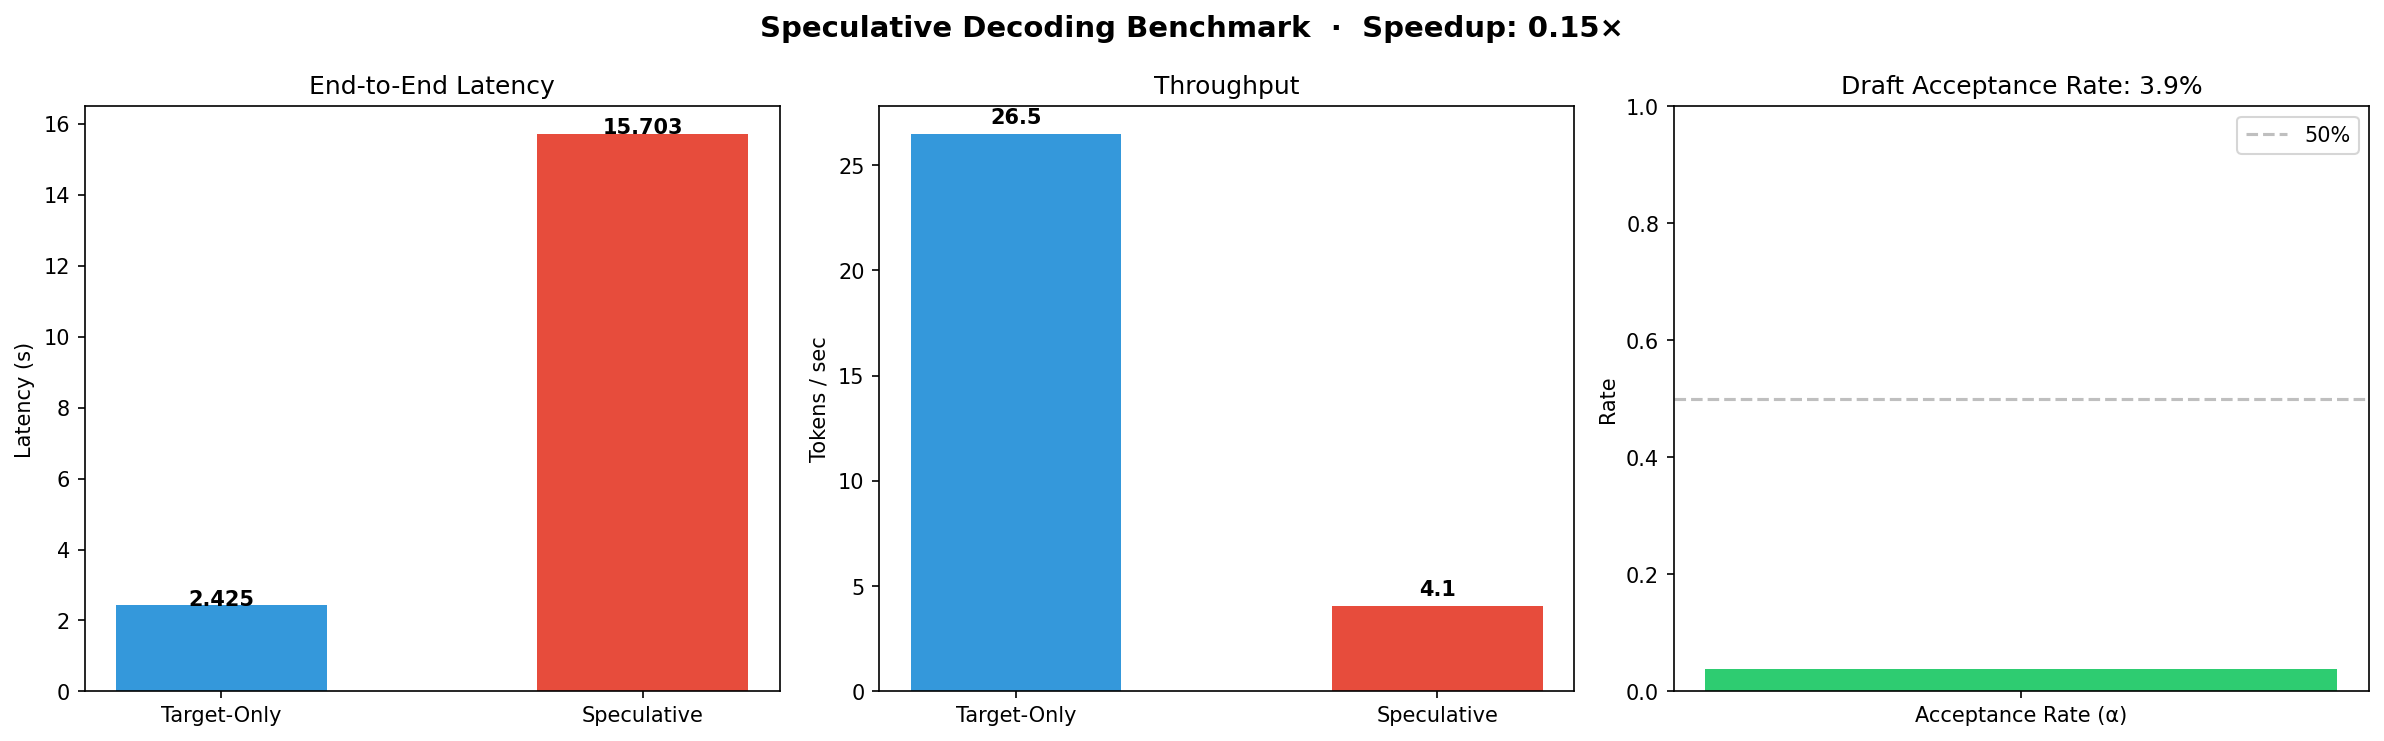

In [28]:
# Benchmark speculative vs standard generation
print('\n' + '='*60)
print('STEP 2: Speculative Decoding Benchmark')
print('='*60)
spec_results = spec_benchmark(
    draft_model_name='Qwen/Qwen2.5-0.5B-Instruct',
    target_model_name='Qwen/Qwen2.5-1.5B-Instruct'
)

from IPython.display import Image, display
display(Image(filename='reports/figures/speculative_benchmark.png'))

---
## Task 6: Streamlit Application

Launch the interactive browser application. On Colab, use localtunnel for external access.

In [ ]:
# To launch the Streamlit app on Colab:
# Method 1: Direct launch (works in local Jupyter)
# !streamlit run src/app/streamlit_app.py

# Method 2: Colab with localtunnel
# !npm install -g localtunnel
# import subprocess
# proc = subprocess.Popen(['streamlit', 'run', 'src/app/streamlit_app.py', '--server.port', '8501'])
# !npx localtunnel --port 8501

print('To launch the Streamlit app:')
print('  streamlit run src/app/streamlit_app.py')
print('\nThe app includes:')
print('  - Eligibility assessment with evidence highlighting')
print('  - Inference benchmark dashboard')
print('  - Report export functionality')
print('  - Clinical disclaimer banner')

---
## Summary: Save All Results

In [29]:
import json

all_results = {
    'classification_metrics': eval_results.get('classification', {}),
    'evidence_metrics': eval_results.get('evidence', {}),
    'kv_cache_benchmark': kv_results,
    'attention_benchmark': attn_results,
    'speculative_benchmark': spec_results
}

with open('reports/all_results.json', 'w') as f:
    json.dump(all_results, f, indent=2, default=str)

print('All results saved to reports/all_results.json')
print('\n=== ASSIGNMENT COMPLETE ===')

All results saved to reports/all_results.json

=== ASSIGNMENT COMPLETE ===


In [30]:
from google.colab import files

# Create a zip containing all generated reports, benchmark plots, and trained adapter weights
!zip -r -q clinical_trial_results.zip reports outputs

# Download directly to your laptop
files.download('clinical_trial_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import os, subprocess
from google.colab import files

# 1. Pull the updated repository files
!rm -rf temp_repo
!git clone -q https://github.com/hamzaa112233/GenAI-Assignment2.git temp_repo
!cp -rf temp_repo/* .
!rm -rf temp_repo

# 2. Ensure TeX packages are installed
!apt-get update -qq && apt-get install -y -qq texlive-latex-base texlive-latex-extra texlive-fonts-recommended &>/dev/null

# 3. Compile inside the 'reports' folder
proc = subprocess.run(['pdflatex', '-interaction=nonstopmode', 'paper.tex'], cwd='reports', capture_output=True, text=True)
subprocess.run(['pdflatex', '-interaction=nonstopmode', 'paper.tex'], cwd='reports', capture_output=True, text=True)

# 4. Check and download
if os.path.exists('reports/paper.pdf'):
    print("SUCCESS! Compiled reports/paper.pdf successfully. Downloading now...")
    files.download('reports/paper.pdf')
else:
    print("LaTeX Output Log:")
    print(proc.stdout[-2500:] if proc.stdout else proc.stderr)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
SUCCESS! Compiled reports/paper.pdf successfully. Downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>